# Support Vector Machine (linear)

Finds the hyperplane `w·x + b = 0` that separates two classes with the widest margin. Trained by subgradient descent on the regularized hinge loss:

```
lam/2 * ||w||^2  +  mean( max(0, 1 - y * (w·x + b)) )
```

Only points inside or beyond the margin (`y * f(x) < 1`) contribute to the gradient — those are the support vectors. `lam` is the regularization strength (large `lam` = wider, softer margin; roughly `1 / C`).

Binary only, linear kernel. Scale features first (the demo uses `StandardScaler`).

## Usage

```python
# (the class is defined in the Implementation section below)

model = LinearSVM(lam=0.01, n_iters=1000).fit(X_train, y_train)
preds = model.predict(X_test)
scores = model.decision_function(X_test)  # signed distance-like score
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class LinearSVM:
    """Binary linear SVM: minimizes  lam/2 * ||w||^2 + mean(max(0, 1 - y * (Xw + b)))
    by full-batch subgradient descent. Features should be on a similar scale."""

    def __init__(self, lam=0.01, lr=0.1, n_iters=1000):
        self.lam = lam
        self.lr = lr
        self.n_iters = n_iters
        self.classes_ = None
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("LinearSVM is binary: needs exactly 2 classes")
        y_pm = 2.0 * y_enc - 1.0  # {0, 1} -> {-1, +1}

        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        for t in range(self.n_iters):
            violators = y_pm * (X @ self.weights + self.bias) < 1  # inside margin or misclassified
            grad_w = self.lam * self.weights - (y_pm[violators] @ X[violators]) / len(y)
            grad_b = -y_pm[violators].sum() / len(y)
            step = self.lr / np.sqrt(t + 1)
            self.weights -= step * grad_w
            self.bias -= step * grad_b
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

## See it work

### 1. The maximum-margin line

A linear SVM does not just separate the classes, it picks the line with the **widest empty street** between them. The dashed lines are the margins (`w·x + b = ±1`); the circled points on or inside them are the **support vectors**, the only points that determine the boundary. Move any other point (without crossing the margin) and the line does not change.

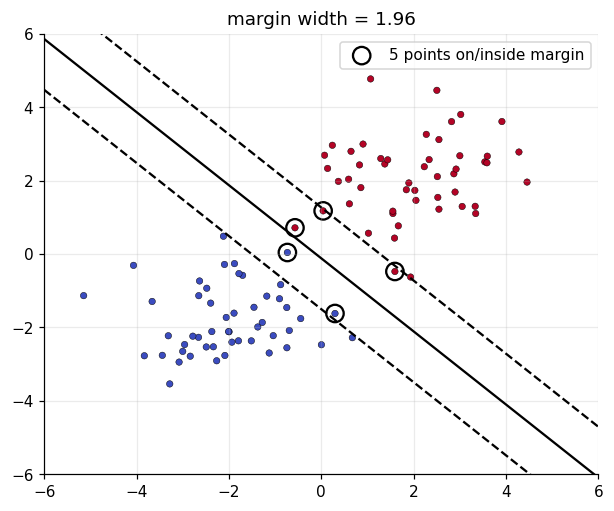

In [3]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=100, centers=[[-2, -2], [2, 2]], cluster_std=1.1, random_state=5)
m = LinearSVM(lam=0.01, n_iters=2000).fit(X, y)
w, b = m.weights, m.bias
score = X @ w + b
sv = np.abs(score) <= 1.0 + 1e-6
xs = np.linspace(-6, 6, 100)
line = lambda off: -(w[0] * xs + b - off) / w[1]
plt.figure(figsize=(6.5, 5.2))
plt.scatter(*X.T, c=y, cmap="coolwarm", s=18, edgecolor="k", linewidth=0.3)
plt.scatter(*X[sv].T, s=130, facecolors="none", edgecolors="k", linewidths=1.5, label=f"{sv.sum()} points on/inside margin")
plt.plot(xs, line(0), "k"); plt.plot(xs, line(1), "k--"); plt.plot(xs, line(-1), "k--")
plt.ylim(-6, 6); plt.xlim(-6, 6); plt.legend(); plt.title(f"margin width = {2 / np.linalg.norm(w):.2f}"); plt.show()

### 2. Regularisation = margin width vs mistakes

The objective is `λ/2‖w‖² + mean(hinge loss)`. Large `λ` prefers a **wide margin** and tolerates points inside it (soft margin); small `λ` punishes any violation and the margin shrinks. On overlapping classes this matters a lot.

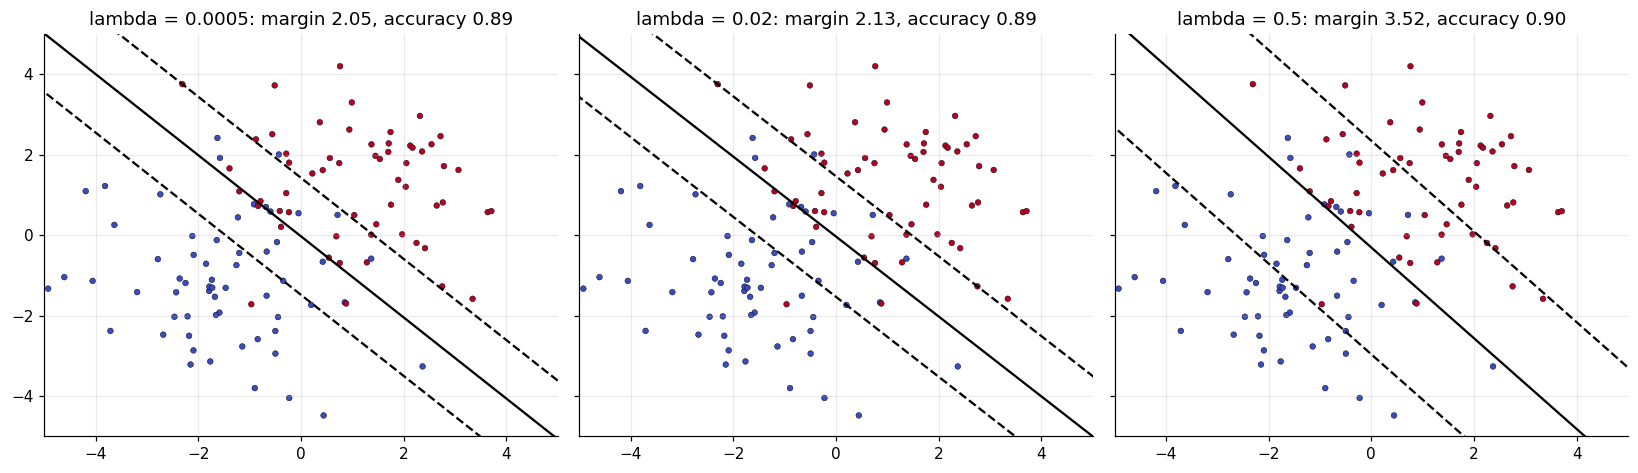

In [4]:
Xo, yo = make_blobs(n_samples=120, centers=[[-1.2, -1.2], [1.2, 1.2]], cluster_std=1.4, random_state=2)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharex=True, sharey=True)
for ax, lam in zip(axes, [0.0005, 0.02, 0.5]):
    mm = LinearSVM(lam=lam, n_iters=3000).fit(Xo, yo); ww, bb = mm.weights, mm.bias
    ax.scatter(*Xo.T, c=yo, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
    for off, st in [(0, "k"), (1, "k--"), (-1, "k--")]: ax.plot(xs, -(ww[0] * xs + bb - off) / ww[1], st)
    ax.set(title=f"lambda = {lam}: margin {2 / np.linalg.norm(ww):.2f}, accuracy {(mm.predict(Xo) == yo).mean():.2f}", xlim=(-5, 5), ylim=(-5, 5))
plt.tight_layout(); plt.show()

### 3. The hinge loss

For a point with true label `y ∈ {−1, +1}` and score `f`, hinge loss is `max(0, 1 − y·f)`: zero once the point is correctly classified **with margin ≥ 1**, then growing linearly. Compared with the logistic loss (smooth, never exactly zero) and the 0-1 loss (what we really want, but flat and non-differentiable).

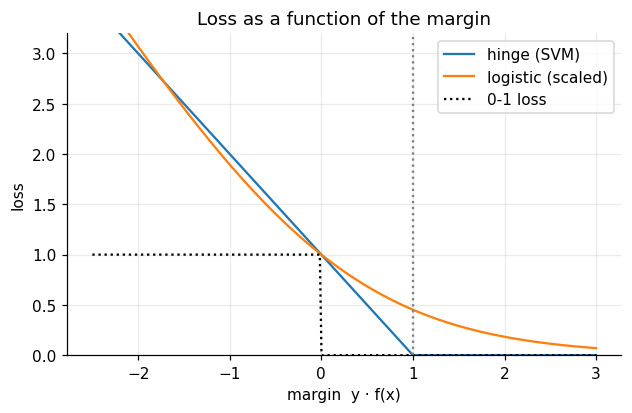

In [5]:
margin = np.linspace(-2.5, 3, 300)
plt.figure(figsize=(6.5, 3.8))
plt.plot(margin, np.maximum(0, 1 - margin), label="hinge (SVM)"); plt.plot(margin, np.log1p(np.exp(-margin)) / np.log(2), label="logistic (scaled)")
plt.plot(margin, (margin < 0).astype(float), "k:", label="0-1 loss"); plt.axvline(1, color="gray", ls=":")
plt.xlabel("margin  y · f(x)"); plt.ylabel("loss"); plt.ylim(0, 3.2); plt.legend(); plt.title("Loss as a function of the margin"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)
scaler = StandardScaler().fit(X_train)  # SVMs need scaled features
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

ours = LinearSVM(lam=0.01, n_iters=1000).fit(X_train, y_train)
theirs = SVC(kernel="linear", C=1.0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("breast cancer test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.03

breast cancer test accuracy: ours=0.9883 sklearn=0.9766


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_separable_blobs_string_labels():
    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(-3, 0.6, (80, 2)), rng.normal(3, 0.6, (80, 2))])
    y = np.array(["neg"] * 80 + ["pos"] * 80)

    model = LinearSVM().fit(X, y)
    assert (model.predict(X) == y).all()
    assert model.weights @ np.array([1.0, 1.0]) > 0  # boundary orientation: "pos" is up-right


def test_margin_is_respected():
    rng = np.random.default_rng(1)
    X = np.vstack([rng.normal(-4, 0.5, (60, 2)), rng.normal(4, 0.5, (60, 2))])
    y = np.array([0] * 60 + [1] * 60)
    model = LinearSVM(n_iters=2000).fit(X, y)
    scores = model.decision_function(X) * (2 * y - 1)
    assert scores.min() > 0.9  # separable data ends up (almost) outside the margin


def test_rejects_multiclass():
    try:
        LinearSVM().fit(np.zeros((3, 2)), np.array([0, 1, 2]))
    except ValueError:
        return
    raise AssertionError("expected ValueError")

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_separable_blobs_string_labels
PASS test_margin_is_respected
PASS test_rejects_multiclass

all 3 tests passed


## Takeaways

- **Use it** for medium-sized, high-dimensional, roughly linearly separable data (text, genomics). The margin gives good generalisation; only support vectors matter.
- **This version** minimises `λ/2‖w‖² + mean hinge` by subgradient descent: for points inside the margin the step is `−y·x`, plus the shrink `λw`. **Scale your features.**
- **Non-linear boundaries:** `17_kernel_svm`. For probabilities use logistic regression (SVM scores are not probabilities).
- **Interview line:** *"Maximise the margin: hinge loss plus `‖w‖²` regularisation; the solution is determined by the support vectors."*